# Wczytanie danych, kontrola struktury i podział na train / valid / test

----
## 0. Importy

In [1]:
import sys; sys.path.insert(0, '..')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score
from src import config as cfg
from src.data import load_data, make_splits, save_splits, load_splits
plt.style.use('default')

----
## 1. Struktura danych

In [2]:
df = load_data()
y = df[cfg.TARGET]
print('wymiary:', df.shape)
print(f'defaulty: {y.sum()} z {len(y)}')
print(f'DR = {y.mean():.2%}')

wymiary: (3000, 223)
defaulty: 412 z 3000
DR = 13.73%


In [3]:
print('duplikaty wierszy:', df.duplicated().sum())
print('duplikaty cech:', df.drop(columns=cfg.TARGET).duplicated().sum())
n_inf = np.isinf(df.select_dtypes('number')).sum()
print('kolumny z inf:', n_inf[n_inf > 0].to_dict())

duplikaty wierszy: 0
duplikaty cech: 0
kolumny z inf: {'wsk_kapital_do_aktywa': 10, 'wsk_plynnosc_biez_1': 929, 'wsk_struktura_kap_wlasnego_s_2': 96}


In [4]:
from pypdf import PdfReader

reader = PdfReader(cfg.ROOT / 'data' / 'Dane_Opis_zmiennych.pdf')
text = '\n'.join(page.extract_text() for page in reader.pages)
documented = {line.split()[0] for line in text.splitlines() if line.strip()}
missing = [c for c in df.columns if c not in documented]

print('zmiennych opisanych w PDF:', len(documented & set(df.columns)), 'z', df.shape[1])
print('kolumny bez opisu:', missing)

zmiennych opisanych w PDF: 217 z 223
kolumny bez opisu: ['wsk_index_aktywne', 'wsk_index_skr_zaw', 'wsk_index_nowe', 'schemat_wsk_bilans', 'schemat_wsk_rzis', 'default']


**Kolumny bez opisu w słowniku danych:**
- `wsk_index_aktywne`, `wsk_index_skr_zaw`, `wsk_index_nowe` – do usunięcia, nie wiadomo, czy były znane w dniu sprawozdania, więc jest ryzyko przecieku.
- `schemat_wsk_bilans`, `schemat_wsk_rzis` – do zostawienia, brak opisu, ale znaczenie wynika z wartości (typ formularza sprawozdania: mikro / mała / pozostałe)

In [5]:
const_cols = []

for c in df.columns:
    if df[c].nunique(dropna=False) <= 1:
        const_cols.append(c)
        print(f'{c:45s} wartość: {df[c].iloc[0]}')

print('kolumny stałe:', const_cols)

szczegolnaFormaPrawna_Symbol                  wartość: 117
Zobowiazania_dostaw_uslug_pow12m_kapitale     wartość: 0.0
kolumny stałe: ['szczegolnaFormaPrawna_Symbol', 'Zobowiazania_dostaw_uslug_pow12m_kapitale']


**Kolumny stałe:**
- `szczegolnaFormaPrawna_Symbol`, `Zobowiazania_dostaw_uslug_pow12m_kapitale` – do usunięcia, nie niosą informacji


**Wszystkie kolumny do usunięcia (DROP_COLS w config):**
- `wsk_index_aktywne`
- `wsk_index_skr_zaw`
- `wsk_index_nowe`
- `szczegolnaFormaPrawna_Symbol`
- `Zobowiazania_dostaw_uslug_pow12m_kapitale`

----
## 2. Podział danych

In [6]:
splits = make_splits(y,cfg.SEED)
save_splits(splits)         # zapis podziału w pliku, na przyszłośc
splits = load_splits()

----
## 3. Kontrola przecieku (anty-leak)

In [7]:
tr = splits['train']
auc = {}

for c in df.drop(columns=cfg.TARGET).select_dtypes('number').columns:
    x = df.loc[tr, c].replace([np.inf, -np.inf], np.nan)   # inf traktujemy tu jak brak
    m = x.notna()
    if x[m].nunique() > 1:
        auc[c] = roc_auc_score(y.loc[tr][m], x[m])

screen = pd.DataFrame({'AUC': auc}).assign(sila=lambda t: (t.AUC - 0.5).abs()).sort_values('sila', ascending=False)
screen['wykluczona'] = screen.index.isin(cfg.DROP_COLS)
screen.to_csv(cfg.TAB_DIR / '01_przesiew_auc.csv')
screen.head(10).round(3)

,AUC,sila,wykluczona
wsk_index_skr_zaw,0.710,0.210,True
wsk_index_nowe,0.693,0.193,True
Kapital_wlasny,0.343,0.157,False
zysk_brutto,0.346,0.154,False
zysk_netto,0.350,0.150,False
wsk_stopa_zysku_sprzedaz,0.351,0.149,False
wsk_zysk_CF_operacyjny,0.356,0.144,False
wsk_zysk_zobowiazania,0.359,0.141,False
podatek_dochodowy,0.359,0.141,False
wsk_ROA,0.359,0.141,False


**Wnioski:** żadna cecha nie przekracza progu alarmowego (AUC jednowymiarowe > 0,85), więc nie widać oczywistej informacji z przyszłości. Najsilniejsze pojedynczo są `wsk_index_skr_zaw` i `wsk_index_nowe` – kolumny bez opisu w słowniku danych, wykluczone z modelowania.

----
## 4. Schemat walidacji

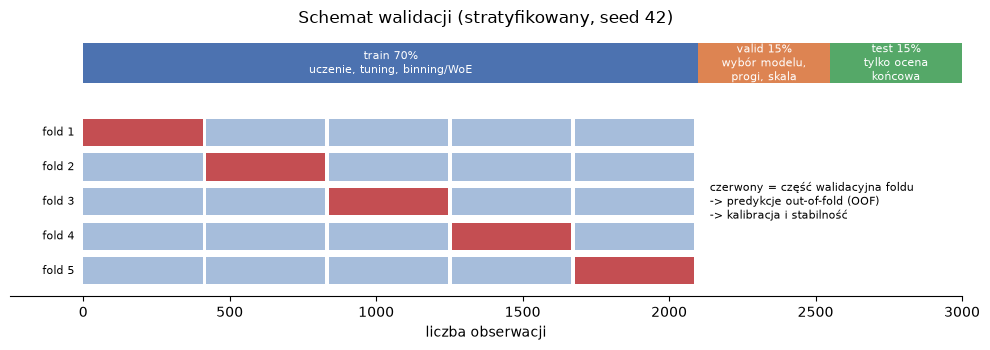

In [8]:
fig, ax = plt.subplots(figsize=(10, 3.6))

n, ntr, nva = len(y), len(splits['train']), len(splits['valid'])

parts = [(0, ntr, '#4C72B0', 'train 70%\nuczenie, tuning, binning/WoE'),
         (ntr, nva, '#DD8452', 'valid 15%\nwybór modelu,\nprogi, skala'),
         (ntr + nva, n - ntr - nva, '#55A868', 'test 15%\ntylko ocena\nkońcowa')]

for x0, w, col, txt in parts:
    ax.barh(5, w, left=x0, color=col)
    ax.text(x0 + w / 2, 5, txt, ha='center', va='center', color='white', fontsize=8)

k = cfg.N_FOLDS; w = ntr / k

for i in range(k):
    for j in range(k):
        ax.barh(3.6 - i * 0.7, w * 0.97, left=j * w, height=0.55, color='#C44E52' if i == j else '#A6BDDB')
    ax.text(-30, 3.6 - i * 0.7, f'fold {i+1}', ha='right', va='center', fontsize=8)
ax.text(ntr + 40, 2.2, 'czerwony = część walidacyjna foldu\n-> predykcje out-of-fold (OOF)\n-> kalibracja i stabilność',fontsize=8, va='center')

ax.set_yticks([]); ax.set_xlim(-250, n); ax.set_xlabel('liczba obserwacji')
ax.set_title('Schemat walidacji (stratyfikowany, seed 42)')
for s in ['top', 'right', 'left']: ax.spines[s].set_visible(False)
plt.tight_layout(); plt.savefig(cfg.FIG_DIR / '01_schemat_walidacji.png', dpi=150);
plt.show()